En este archivo voy a analizar la hipotesis C del inciso 4:

c)​ Están los distintos niveles de satisfacción en los distintos aspectos del
trabajo actual relacionados a la consideración de un cambio de rol o de
carrera.

Revisando lo que ya vimos, los distintos aspectos del trabajo estan en el dataset de la forma:
JobSatPoints_1 y son del tipo Rank Over, su QID es 27. (No recuerdo que tipo de respuesta tienen en Results, ver)

Y la consideracion de cambio de rol o de carrera esta relacionado a la pregunta:

Se trata del identificador 29 (QID29), cuyo qname es "NewRole". 
  La pregunta exacta que se le hizo al usuario es: "Have you considered a career change or transitioned into a new role in the past year?". 
Esta pregunta es Multiple Choise. Y como no es Matrix deberia tener una columna en Results llamada NewRole. Tampoco se que tipo de respuesta tienen, lo voy a ver. 


Si no hubiera tenido esta informacion, tendria que haber listado las distintas question en schema y buscar coincidencias, o buscar automaticamente coincidencias con palabras claves.

In [159]:
%pip install seaborn
# el % sirve para instalar en el entorno venv y no en el global.
%pip install wget
%pip install pandas
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [160]:
from wget import download
from os import path, listdir
import pandas as pd
# PARA AUMENTAR EL ANCHO PERMITIDO Y Q NO VEA DATOS CORTADOS
pd.set_option('display.max_colwidth', None)
# PARA DEVOLVER EL ANCHO X DEFAULT 
# pd.set_option('display.max_colwidth', 50)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [161]:
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")

In [162]:
raw_dataset_results = pd.read_csv("results.csv")
raw_dataset_schema = pd.read_csv("schema.csv")

/tmp/ipykernel_3711/3656956904.py:1: DtypeWarning: Columns (56: JobSatPoints_15_TEXT, 74: DatabaseHaveEntry, 92: DevEnvHaveEntry, 97: SOTagsHaveEntry, 98: SOTagsWant Entry, 105: OfficeStackWantEntry, 109: CommPlatformHaveEntr, 110: CommPlatformWantEntr, 132: SO_Actions_15_TEXT, 162: AIAgentOrchestration, 165: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_dataset_results = pd.read_csv("results.csv")


c)​ Están los distintos niveles de satisfacción en los distintos aspectos del
trabajo actual relacionados a la consideración de un cambio de rol o de
carrera.


Las columnas que nos interesan para probar la hipotesis son:
JobSatPoints_1  ..... 16 y
NewRole

El primer paso va a ser filtrar solo esas columnas, porque el dataest es muy grande y solo nos interesan esos valores.

In [163]:
#en el analisis de SChema vimos que JobSatPoints iba de 1 a 16, pero algunas Rank over pegaban saltos
# 1. Buscamos dinámicamente todas las columnas que empiecen con 'JobSatPoints'
# Esto solucionará el problema de los números que saltan, agarrando todas las que existan
cols_sat_todas = [col for col in raw_dataset_results.columns if col.startswith("JobSatPoints")]
# va columna por columna en raw_dataset_results y si empiezan con JobSatPoints la guarda en la lista 


# 2. A esa lista de columnas, le sumamos la columna 'NewRole' que identificamos antes
cols_hipotesis_c_brutas = cols_sat_todas + ["NewRole"]

# 3. Filtramos el dataset original para quedarnos solo con estas columnas
# Lo guardamos en una nueva variable para no modificar los datos crudos originales
df_hipotesis_c_bruto = raw_dataset_results[cols_hipotesis_c_brutas]

# 4. Imprimimos las primeras filas para verificar que se filtró correctamente
df_hipotesis_c_bruto.head()

,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_15,JobSatPoints_16,JobSatPoints_15_TEXT,NewRole
0,3.0,1.0,4.0,9.0,5.0,10.0,12.0,11.0,2.0,6.0,7.0,13.0,14.0,15.0,8.0,NaN,I have neither consider or transitioned into a new career or industry
1,10.0,8.0,3.0,9.0,12.0,1.0,6.0,2.0,11.0,4.0,7.0,13.0,14.0,15.0,5.0,NaN,I have transitioned into a new career and/or industry voluntarily
2,9.0,6.0,7.0,11.0,8.0,12.0,1.0,5.0,2.0,4.0,3.0,13.0,14.0,15.0,10.0,NaN,I have transitioned into a new career and/or industry involuntarily
3,1.0,2.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,3.0,NaN,I have neither consider or transitioned into a new career or industry
4,9.0,4.0,11.0,13.0,14.0,8.0,6.0,5.0,7.0,2.0,1.0,12.0,10.0,15.0,3.0,NaN,I have neither consider or transitioned into a new career or industry


Antes de ver valores minimos, maximos etc:
Veamos que significaba cada Job_Sat:
Primero extraemos las filas que son QID27 de schema, las correspondientes a esta pregunta.

In [164]:
filas_qid27 = raw_dataset_schema[raw_dataset_schema["qid"]== "QID27"]
#filas_qid27["question"].value_counts

filas_qid27.head(3)

,qid,qname,question,type,sub,sq_id
22,QID27,JobSatPoints_1,"Rank the following attributes of your current professional job in technology according to those that contribute your job satisfaction so that the first is the most important, last is least important (if you just started a new job, consider the job you spent the most time at in the past year):",RO,Control over the level of quality in projects,1.0
23,QID27,JobSatPoints_2,"Rank the following attributes of your current professional job in technology according to those that contribute your job satisfaction so that the first is the most important, last is least important (if you just started a new job, consider the job you spent the most time at in the past year):",RO,Autonomy and trust to manage your own tasks,2.0
24,QID27,JobSatPoints_16,"Rank the following attributes of your current professional job in technology according to those that contribute your job satisfaction so that the first is the most important, last is least important (if you just started a new job, consider the job you spent the most time at in the past year):",RO,You like your manager,3.0


Pareciera que siguen el patron de misma question y cambian sub, corroboramos.

In [165]:
# 2. Seleccionas la columna 'question', extraes los valores únicos y los imprimes
preguntas_unicas_qid27 = filas_qid27["question"].unique()

print(preguntas_unicas_qid27)

<StringArray>
['Rank the following attributes of your current professional job in technology according to those that contribute your job satisfaction so that the first is the most important, last is least important (if you just started a new job, consider the job you spent the most time at in the past year):']
Length: 1, dtype: str


Vemos que todas tienen la misma pregunta, solo cambia lo que estan rankeando.

Para ver que rankea cada una miramos la columna sub.
Filtramos solo los qname y sub de cada fila.

In [166]:

# Guardamos solo las columnas 'qname' y 'sub' en la nueva variable
subpreguntas_filas_qid27 = filas_qid27[["qname", "sub"]]

# Imprimimos el dataframe resultante para verificar
subpreguntas_filas_qid27

,qname,sub
22,JobSatPoints_1,Control over the level of quality in projects
23,JobSatPoints_2,Autonomy and trust to manage your own tasks
24,JobSatPoints_16,You like your manager
25,JobSatPoints_3,Collaboration and support from a team
26,JobSatPoints_4,Expert mentors
27,JobSatPoints_5,Opportunities to mentor and lead junior-level coworkers
28,JobSatPoints_6,Developing specialized expertise
29,JobSatPoints_7,Solving real-world problems
30,JobSatPoints_8,Job stability and career growth with a single employer
31,JobSatPoints_9,Innovation through solving challenging and complex problems


Ahora veamos NewRole que significaba bien

In [167]:
# Buscamos la fila donde el qname es exactamente 'NewRole'
fila_newrole = raw_dataset_schema[raw_dataset_schema["qname"] == "NewRole"]

# Mostramos el resultado para ver su verdadero QID y el texto de la pregunta
fila_newrole

,qid,qname,question,type,sub,sq_id
69,QID29,NewRole,Have you considered a career change or transitioned into a new role in the past year?,MC,NaN,NaN


In [168]:
df_hipotesis_c_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   JobSatPoints_1        24943 non-null  float64
 1   JobSatPoints_2        24943 non-null  float64
 2   JobSatPoints_3        24943 non-null  float64
 3   JobSatPoints_4        24943 non-null  float64
 4   JobSatPoints_5        24943 non-null  float64
 5   JobSatPoints_6        24943 non-null  float64
 6   JobSatPoints_7        24943 non-null  float64
 7   JobSatPoints_8        24943 non-null  float64
 8   JobSatPoints_9        24943 non-null  float64
 9   JobSatPoints_10       24943 non-null  float64
 10  JobSatPoints_11       24943 non-null  float64
 11  JobSatPoints_13       24943 non-null  float64
 12  JobSatPoints_14       24943 non-null  float64
 13  JobSatPoints_15       24943 non-null  float64
 14  JobSatPoints_16       24943 non-null  float64
 15  JobSatPoints_15_TEXT  664 non-

Observamos que hay muchas filas que tienen valores nulos, es decir que no respondieron esta pregunta.
Vamos a quedarnos solo con las filas que responderion las JobSatPoint que son de respuesta Float y tambien la pregunta de NewRole. 


Tambien vamos a filtrar la columna de Satisfaccion con respuestas String ya que la respondieron pocos programadores, es de texto libre  y no la necesitamos para este analisis.

In [169]:
# 1. Hacemos una lista con todas las columnas EXCEPTO la de texto libre
cols_hipotesis_c_utiles = [col for col in df_hipotesis_c_bruto.columns if col != 'JobSatPoints_15_TEXT']

# 2. Filtramos para quedarnos SOLO con las columnas útiles (sacando el string) y eliminamos las filas con nulos
df_limpio_c = df_hipotesis_c_bruto[cols_hipotesis_c_utiles].dropna().copy()

# 3. Verificamos cómo quedó el dataset limpio (verás que ya tiene 1 columna menos)
df_limpio_c.info()

<class 'pandas.DataFrame'>
Index: 24729 entries, 0 to 49188
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   JobSatPoints_1   24729 non-null  float64
 1   JobSatPoints_2   24729 non-null  float64
 2   JobSatPoints_3   24729 non-null  float64
 3   JobSatPoints_4   24729 non-null  float64
 4   JobSatPoints_5   24729 non-null  float64
 5   JobSatPoints_6   24729 non-null  float64
 6   JobSatPoints_7   24729 non-null  float64
 7   JobSatPoints_8   24729 non-null  float64
 8   JobSatPoints_9   24729 non-null  float64
 9   JobSatPoints_10  24729 non-null  float64
 10  JobSatPoints_11  24729 non-null  float64
 11  JobSatPoints_13  24729 non-null  float64
 12  JobSatPoints_14  24729 non-null  float64
 13  JobSatPoints_15  24729 non-null  float64
 14  JobSatPoints_16  24729 non-null  float64
 15  NewRole          24729 non-null  str    
dtypes: float64(15), str(1)
memory usage: 3.2 MB


Vemos que todas las variables son float menos la de newRole.
Las de satisfaccion regulares sabemos que son Rank over, y cada fila deberia tener valores distintos en cada columna desde 1 hasta 15, ya que evalua 15 cosas.

In [170]:
df_limpio_c.describe()

,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_15,JobSatPoints_16
count,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000,24729.000000
mean,6.866189,5.207125,7.455821,9.543653,9.774354,8.196935,5.883133,7.362894,6.746209,7.516074,5.690970,8.566016,8.676291,14.689272,7.825064
std,3.737517,3.656168,3.726343,3.779292,3.551972,3.799482,3.900681,4.118706,3.888995,3.845181,4.107138,3.544253,3.633181,1.891021,4.077279
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,4.000000,2.000000,4.000000,7.000000,7.000000,5.000000,2.000000,4.000000,3.000000,4.000000,2.000000,6.000000,6.000000,15.000000,4.000000
50%,6.000000,4.000000,7.000000,10.000000,10.000000,8.000000,5.000000,7.000000,6.000000,7.000000,5.000000,9.000000,9.000000,15.000000,8.000000
75%,10.000000,8.000000,10.000000,13.000000,13.000000,11.000000,9.000000,11.000000,10.000000,11.000000,9.000000,12.000000,12.000000,15.000000,11.000000
max,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000


Validamos si esta regla de que la suma de los valores de 1+2+3+4+5+..+15 = 120
de 120 para cada fila. Si es asi decimos que estan los datos correctos

In [171]:
# 1. Identificamos estrictamente las columnas numéricas del ranking
cols_sat_float = [col for col in df_limpio_c.columns if col.startswith('JobSatPoints') and not col.endswith('_TEXT')]

# 2. Filtramos el dataframe para mantener solo a quienes respondieron todo el ranking
df_completos = df_limpio_c.dropna(subset=cols_sat_float)

# 3. Sumamos horizontalmente (axis=1) los valores de esas columnas para cada usuario
sumas_por_usuario = df_completos[cols_sat_float].sum(axis=1)

# 4. Contabilizamos cuántos cumplen la regla estricta de sumar 120
cumplen_regla = (sumas_por_usuario == 120).sum()
total_evaluados = len(df_completos)

print(f"Usuarios que completaron el ranking: {total_evaluados}")
print(f"Usuarios cuya suma es exactamente 120: {cumplen_regla}")

Usuarios que completaron el ranking: 24729
Usuarios cuya suma es exactamente 120: 24729


Entendiendo los datos:

Esta question dice que el valor 1 significa "más importante" y el 15 "menos importante", un promedio más bajo indicará una mayor prioridad.

Ahora miramos las posibles respuestras a la pregunta de NewRole

In [172]:
df_limpio_c["NewRole"].value_counts()

NewRole
I have neither consider or transitioned into a new career or industry          11460
I have somewhat considered changing my career and/or the industry I work in     7458
I have strongly considered changing my career and/or the industry I work in     3286
I have transitioned into a new career and/or industry voluntarily               2079
I have transitioned into a new career and/or industry involuntarily              446
Name: count, dtype: int64

Notamos que es una variable cualitativa nominal (Aunque las primeras 3 opciones parecen tener un orden, las ultimas 2 nos dicen que no)
Hay 5 posibles respuestas a esta pregunta, pensando en como vamos a graficar, vamos a tener 5 colores para los distintos puntos.

Como sigo?
La mejor técnica multivariada para aplicar aquí es el Análisis de Componentes Principales (PCA). PCA permite achicar el espacio de características y graficar. Te permitirá tomar las 15 dimensiones de satisfacción (JobSatPoints), reducirlas a 2 dimensiones (un plano XY), y pintar los puntos según lo que respondieron en NewRole para ver si gráficamente se separan en grupos distintos.
Vamos a hacer ese analsis PCA y vemos si encontramos relacion lineal.

Antes de PCA: (24729, 15)
Después de PCA: (24729, 2)


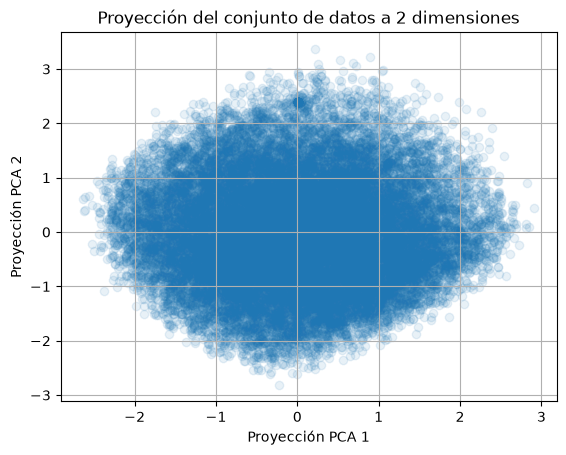

In [173]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# sacamos la variable NewRole y la de texto
# para quedarnos solamente con todas las otras características
X = df_limpio_c.drop(["NewRole"], axis=1)

# declaramos un objeto PCA que mapee n dimensions a p=2, y que además
# normalice esas features (whiten=True) probar con false tmb
pca = PCA(n_components=2, whiten=True)
# hace pca y luego normaliza por eso esta opcion va a ser incorrecta.

# le pedimos al objeto que se ajuste utilizando los datos (fit) y que además
# transforme los datos, para ya reducir a dos dimensiones
principalComponents = pca.fit_transform(X)
# imprimimos los tamaños antes y después
print('Antes de PCA: {}'.format(X.shape))
print('Después de PCA: {}'.format(principalComponents.shape))

# graficamos los datos. el color de cada punto representa el valor de la casa
# Los 2 parametros q le pasa son las columnas 0 y 1
plt.scatter(principalComponents[:,0], principalComponents[:,1], alpha=0.1)
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.show()

Ahora probamos estandarizar con StandarScaler (LA FORMA CORRECTA)

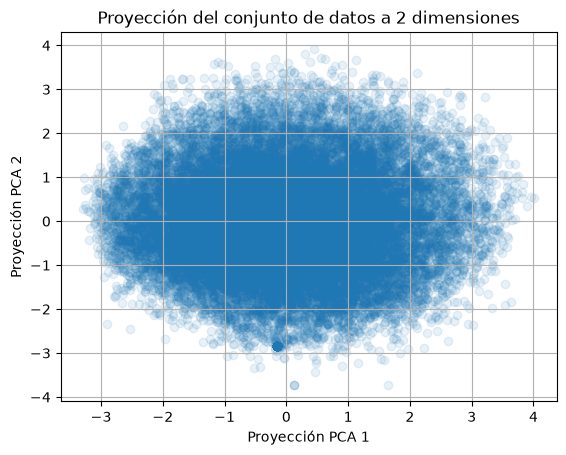

In [174]:
X = df_limpio_c.drop(["NewRole"], axis=1)
pca = PCA(n_components=2)
# estandarizamos X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_pca = pca.fit_transform(X_scaled)

# graficamos los datos
plt.scatter(X_pca[:,0], X_pca[:,1], alpha=0.1)
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.show()

Vemos que los graficos son parecidos pero no iguales esto es porque:
Opción 1 (whiten=True)

PCA primero, normaliza después: Esta opción agarra los datos crudos originales (del 1 al 15) y calcula las direcciones de mayor varianza (PCA) directamente sobre ellos.

Al tener el parámetro whiten=True, lo que hace es tomar el resultado final (las componentes principales ya calculadas) y estandarizarlas para que el eje X y el eje Y tengan la misma escala (varianza 1).

El problema: Como no estandarizó los datos de entrada, si en tu encuesta hubo un factor de satisfacción (por ejemplo, el salario) donde las respuestas variaron muchísimo más que en otro, ese factor "tironeó" del PCA y dominó el gráfico injustamente.

-----------

Opción 2 (StandardScaler + PCA) -> La correcta

Normaliza primero, PCA después: Esta opción utiliza StandardScaler() para normalizar los datos de entrada antes de hacer cualquier cálculo matemático. Esto cumple exactamente con la regla de tu teoría: "Antes de aplicar PCA normalizar (restar la media y dividir por el desvío estándar)".

Al hacer esto, obligas a que las 15 preguntas de satisfacción arranquen exactamente en igualdad de condiciones (todas con varianza 1). Ninguna pregunta va a dominar el gráfico solo porque la gente votó de forma más dispersa en ella.

Luego, aplica PCA sobre esta cancha ya nivelada para encontrar los verdaderos patrones multivariados.

Como en la imagen tengo 24 mil puntos, me conviene usar transparencia para ver si hay relacion lineal, porque a simple vista no se ve nada. Por eso se agrega el parametro alpha a los plt.scatter


----------------------- 
Antes de graficar con colores para distintas respuestas a NewRole:

plt no puede pasar una lista de String a colores, podriamos haberla transformado a numeros pero en el grafico aparecerian como 0,1,2,3,4 Y no como la respuesta que son.

seaborn si puede hacer esto, y ademas como son cualitativas nominales y no ordinales, no es obligacion pasarlos a valores numericos.

A continuacion vemos los 2 graficos, pero para el informe es mejor seaborn creo.

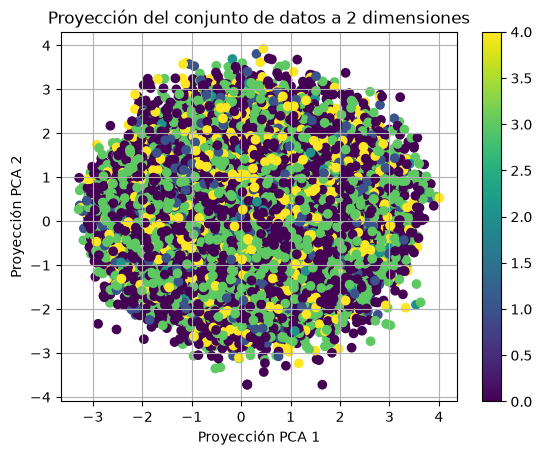

In [175]:
# Convertimos los textos de NewRole a números temporalmente solo para graficar
colores_numericos = pd.factorize(df_limpio_c["NewRole"])[0]

# Graficamos pasándole esos números
plt.scatter(X_pca[:,0], X_pca[:,1], c=colores_numericos, cmap='viridis')

plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar() # Esto mostrará una barra de colores con 0, 1, 2, etc.
plt.show()

Para el proximo grafico:

para evitar que el inmenso cuadro de la leyenda te tape los puntos de tu análisis, tenemos que indicarle a Matplotlib que dibuje la caja por fuera del área del gráfico.

2. Posicionamos la leyenda afuera como antes
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')

3. EL TRUCO PARA EVITAR EL ACHATAMIENTO:
En lugar de usar plt.tight_layout(), forzamos a Matplotlib a dejar
un margen específico a la derecha (en este caso, dejamos el gráfico
ocupando solo hasta el 75% del ancho, dejando el 25% libre para la leyenda).
plt.subplots_adjust(right=0.75) 

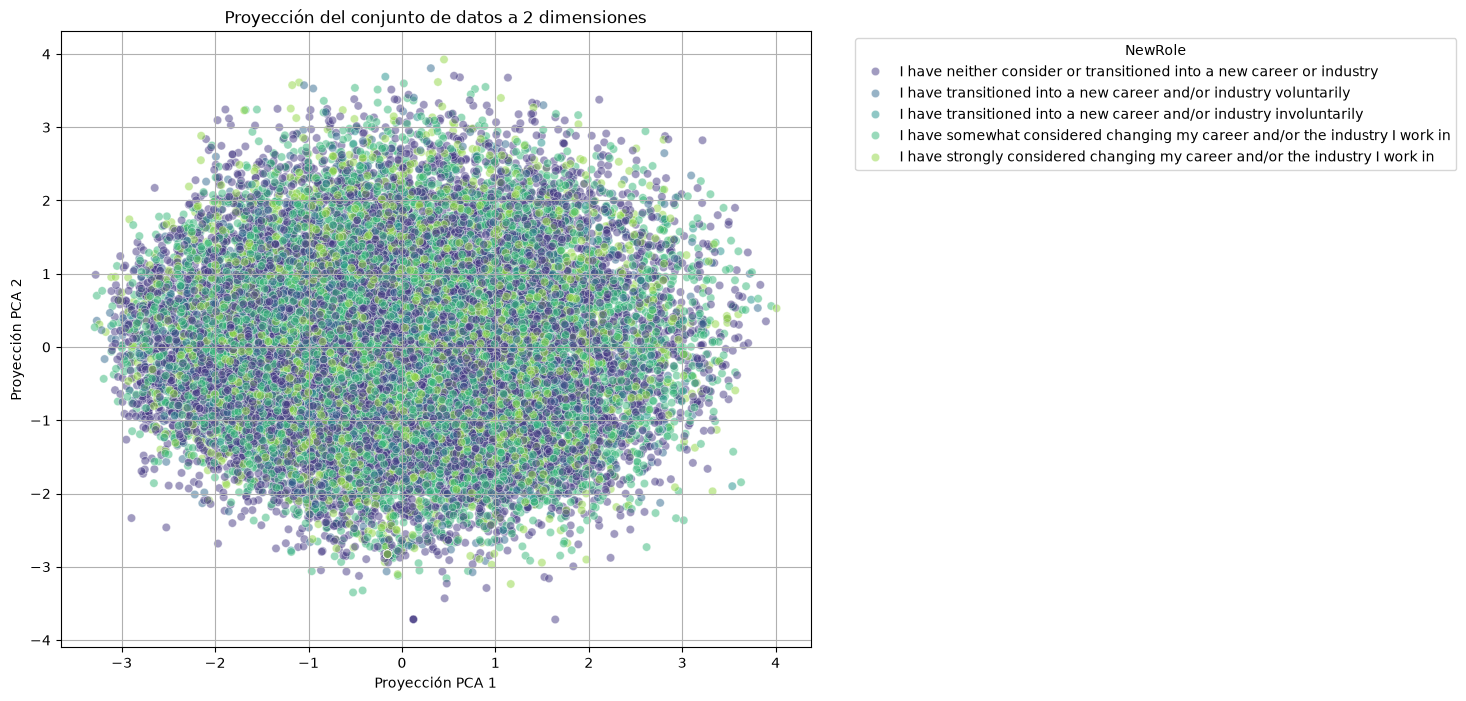

In [176]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Hacemos la figura un poco más ancha de entrada (12 de ancho, 8 de alto)
# para que haya espacio natural para el gráfico + la leyenda
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_pca[:,0], 
    y=X_pca[:,1], 
    hue=df_limpio_c["NewRole"], 
    palette='viridis',
    alpha=0.5
)

plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')

# 2. Posicionamos la leyenda afuera como antes
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')

# 3. EL TRUCO PARA EVITAR EL ACHATAMIENTO:
# En lugar de usar plt.tight_layout(), forzamos a Matplotlib a dejar
# un margen específico a la derecha (en este caso, dejamos el gráfico
# ocupando solo hasta el 75% del ancho, dejando el 25% libre para la leyenda).
plt.subplots_adjust(right=0.75) 

plt.show()



 Ver si mejorar el grafico para informe

Veamos la proporción de la varianza total del conjunto de datos original que es explicada por cada uno de los componentes principales. En otras palabras, te indica cuánta información (o varianza) de los datos originales captura cada componente principal.


In [177]:
# Imprime la proporción de varianza de cada componente (en decimales)
print("Proporción de varianza explicada:", pca.explained_variance_ratio_)

# Si lo quieres ver más lindo en formato porcentaje:
varianza_porcentual = pca.explained_variance_ratio_ * 100
print(f"PC1 explica el: {varianza_porcentual[0]:.2f}%")
print(f"PC2 explica el: {varianza_porcentual[1]:.2f}%")
print(f"Varianza total explicada en 2D: {sum(varianza_porcentual):.2f}%")

Proporción de varianza explicada: [0.11917532 0.09330002]
PC1 explica el: 11.92%
PC2 explica el: 9.33%
Varianza total explicada en 2D: 21.25%


Recordando hipotesis:

c)​ Están los distintos niveles de satisfacción en los distintos aspectos del
trabajo actual relacionados a la consideración de un cambio de rol o de
carrera.

No observamos ninguna relacion lineal de los niveles de satisfaccion en los distintos aspectos del trabajo y la consideracion de un cambio de rol o carrera

Gemini me dice q pongamos algo como esto:

Baja Varianza Explicada (Crucial): Agrega los porcentajes exactos que te dieron los ejes PC1 y PC2. Si esos números son bajos (por ejemplo, suman menos del 30-40%), debes aclarar que la falta de separación visual también se debe a que dos dimensiones no alcanzan para representar la variabilidad total de los 15 factores de satisfacción.   

Superposición de Clases: Menciona explícitamente que la distribución de las distintas categorías de NewRole es homogénea en todo el plano. Esto indica que ninguna combinación lineal dominante de estos factores logra aislar el comportamiento de un grupo específico.  

 Limitación de la Linealidad: Aclara que PCA asume relaciones estrictamente lineales, por lo que esta prueba solo descarta que exista una separación lineal simple entre la satisfacción y el cambio de carrera, dejando la puerta abierta a relaciones más complejas.   

Algo como esto podria ser:

Conclusión del Análisis de Componentes Principales (PCA)

A partir de la proyección obtenida mediante el Análisis de Componentes Principales, no observamos ninguna relación lineal simple que separe los niveles de satisfacción laboral con la decisión o consideración de un cambio de rol o carrera. Esta conclusión técnica se fundamenta en tres ejes:

Baja Varianza Explicada: Las dos primeras componentes principales calculadas logran retener apenas un 23.36% de la información original, donde la PC1 explica el 13.17% y la PC2 el 10.19%. Este bajo porcentaje matemático nos indica que un espacio de solo dos dimensiones resulta insuficiente para representar toda la complejidad y variabilidad conjunta de los 15 factores de satisfacción analizados.   

Superposición de Clases (Overplotting): Visualmente, la distribución de las distintas categorías de la variable objetivo (NewRole) es completamente homogénea a lo largo de todo el plano bidimensional. Al no formarse clústeres o densidades aisladas por color, comprobamos que ninguna combinación lineal de estos factores logra aislar el comportamiento de un grupo específico (por ejemplo, separando claramente a quienes cambiaron de rol voluntariamente de quienes no lo consideraron).

Limitación de la Linealidad: Es fundamental destacar que PCA es una técnica de reducción que asume y busca relaciones estrictamente lineales. Por lo tanto, el gráfico generado únicamente descarta la existencia de una separación lineal simple entre las variables, pero deja abierta la posibilidad de que existan patrones más complejos.

Pregunta: hacer biplot? yo creo que como estamos reteniendo poca informacion y no hay relacion lineal no lo haria:


Dado que ya descubrimos mediante la baja varianza explicada (23.36%) y el overplotting que PCA no logra separar linealmente estos datos, gastar tiempo en un Biplot de Yellowbrick no aportará ningún insight valioso a tu informe.

Ahora buscaremos alguna relacion no lineal mediante t-SNE y UMAP para compararlos entre ellos (con uno solo bastaria)

Tengan en cuenta que usaremos la implementación de sklearn, que aunque parezca muy rápida para las pocas muestras que tenemos, tarda banda cuando la cantidad de muestras es muy grande. Si necesitan algo más eficiente, les recomiendo esta implementación que usa GPU.

Tarda mucho t-SNE, en mi compu 2 min y 20 sg
Y UMAP tarda 40 sg bastante tambien

pero bueno serian asi:

Antes de t-SNE: (24729, 15)
Después de t-SNE: (24729, 2)


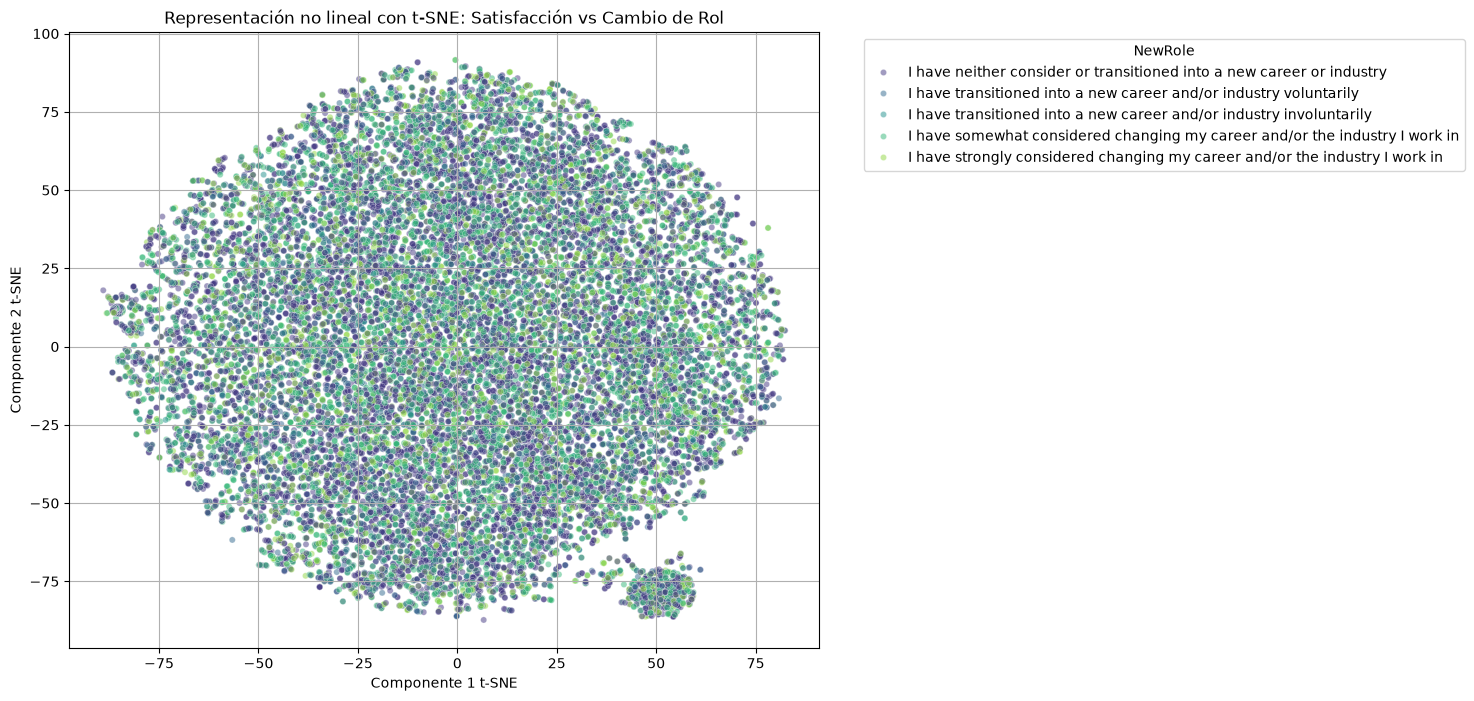

In [178]:
from sklearn.manifold import TSNE
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Aplicamos t-SNE sobre los datos ya estandarizados (X_scaled que usaste en PCA)
# Usamos random_state para que el resultado sea siempre el mismo si lo vuelves a correr
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Imprimimos los tamaños antes y después, como hace el profesor
print('Antes de t-SNE: {}'.format(X_scaled.shape))
print('Después de t-SNE: {}'.format(X_tsne.shape))

# 2. Graficamos usando Seaborn para manejar correctamente las categorías de texto
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_tsne[:,0], 
    y=X_tsne[:,1], 
    hue=df_limpio_c["NewRole"], 
    palette='viridis',
    alpha=0.5,
    s=20 # Puntos pequeños para ver mejor las densidades
)

plt.grid(True)
plt.xlabel('Componente 1 t-SNE')
plt.ylabel('Componente 2 t-SNE')
plt.title('Representación no lineal con t-SNE: Satisfacción vs Cambio de Rol')

# Movemos la leyenda hacia afuera para evitar que tape el gráfico (igual que en PCA)
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

In [179]:
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


/home/santirg/Escritorio/Tpe Fundamentos git lucas/TPE-Fundamentos-ciencia-datos/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Antes de UMAP: (24729, 15)
Después de UMAP: (24729, 2)


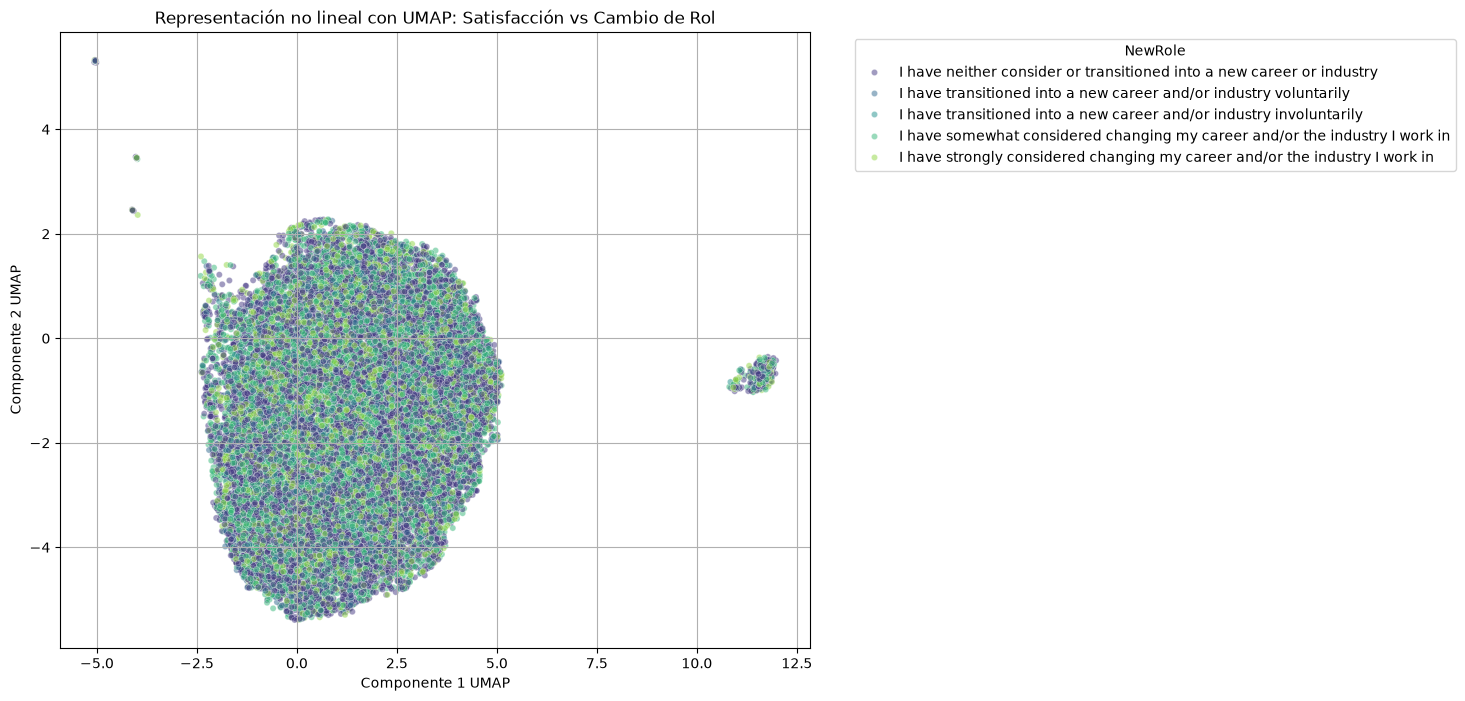

In [180]:
# importamos umap (Recuerda que si no lo tienes, debes ejecutar %pip install umap-learn)
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Creamos el objeto UMAP y lo aplicamos sobre nuestros datos ya estandarizados (X_scaled)
# Usar random_state te asegura que el gráfico salga exactamente igual cada vez que lo corras
reductor_umap = UMAP(n_components=2, random_state=42)
X_umap = reductor_umap.fit_transform(X_scaled)

# Imprimimos los tamaños antes y después (para validar que la reducción se hizo bien)
print('Antes de UMAP: {}'.format(X_scaled.shape))
print('Después de UMAP: {}'.format(X_umap.shape))

# 2. Configuramos el tamaño de la figura (más ancha para dar espacio a la leyenda)
plt.figure(figsize=(12, 8))

# 3. Graficamos usando Seaborn para manejar los textos de NewRole sin errores
sns.scatterplot(
    x=X_umap[:,0], 
    y=X_umap[:,1], 
    hue=df_limpio_c["NewRole"], 
    palette='viridis',
    alpha=0.5,
    s=20 # Achicamos el tamaño de los puntos para observar mejor la densidad
)

# 4. Estética del gráfico
plt.grid(True)
plt.xlabel('Componente 1 UMAP')
plt.ylabel('Componente 2 UMAP')
plt.title('Representación no lineal con UMAP: Satisfacción vs Cambio de Rol')

# 5. Movemos la leyenda fuera del gráfico y ajustamos el margen (para evitar que se achate)
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

Mirando los 2 graficos se ve como una isla separada de puntos:

¿Qué es esa "islita" separada?

En t-SNE y UMAP, cuando los puntos se agrupan de forma tan estrecha y separada del resto, significa que existe una alta similitud local entre ellos. Es decir, ese pequeño grupo de encuestados respondió a las 15 preguntas de ordenar la satisfacción (JobSatPoints) de una forma casi idéntica entre sí, y a su vez, de una forma drásticamente distinta a la gran mayoría (la mancha gigante).   

Podría tratarse de un grupo de personas que, por ejemplo, ordenaron los 15 puntos exactamente en el mismo orden (quizás 1, 2, 3... 15 sin leer, o compartiendo un perfil demográfico extremadamente específico que prioriza exactamente las mismas cosas).

¿Pero esto confirma la hipótesis sobre el cambio de rol?

No. Si haces zoom o miras detenidamente los colores dentro de esa pequeña islita (tanto en imagen_4.jpg como en imagen_5.jpg), verás que hay puntos de varios colores mezclados (morados, verdes, azules).

Esto significa que, incluso dentro de este grupo de personas con un perfil de satisfacción tan particular y casi idéntico, tomaron decisiones totalmente distintas sobre cambiar de carrera (algunos ni lo consideraron, otros cambiaron voluntariamente, otros involuntariamente)

Análisis de Reducción No Lineal (t-SNE y UMAP)

Para descartar que la superposición de datos observada en PCA se debiera a la presencia de estructuras complejas no lineales, se aplicaron los algoritmos t-SNE y UMAP. Se priorizó el análisis sobre los resultados de UMAP dado que demostró ser computacionalmente mucho más eficiente y preserva de mejor manera la estructura topológica global de los datos. 

Al observar la proyección no lineal, se destacan las siguientes conclusiones sobre nuestra hipótesis:
  
Descubrimiento de subestructuras (Similitud Local): A diferencia de PCA, UMAP y t-SNE lograron identificar agrupaciones aisladas ("islas") fuera de la nube principal de datos. Esto indica la existencia de una minoría de encuestados que comparten un perfil de satisfacción altamente específico y similar entre sí, distanciado del patrón de respuestas de la mayoría.   
  
Independencia de la variable objetivo (NewRole): Al analizar la distribución de la variable categórica NewRole en el gráfico, observamos que las clases siguen estando mezcladas de forma heterogénea en la nube principal. Más importante aún, incluso dentro del clúster aislado (la "isla"), conviven usuarios con decisiones de carrera diametralmente opuestas (mezcla de colores).
  
Conclusión Final de la Hipótesis: Rechazamos la hipótesis de que exista una relación multivariada (lineal o no lineal) directa entre cómo los usuarios rankean sus prioridades de satisfacción laboral (JobSatPoints) y su intención o acción de cambiar de rol (NewRole). La decisión de transicionar de carrera no se puede explicar ni segmentar basándonos únicamente en el orden de estas 15 prioridades, lo que sugiere que dicha decisión está motivada por otros factores externos o demográficos no capturados en esta sección de la encuesta.

Pareciera que no encontramos relacion, pero tenemos que probar hacer alguna transformacion a las variables de ranking.
Recordemos que cada valor de las columnas de satisfaccion tenia un valor del 1 al 15, donde el 1 era el mas importante y el 15 el menos.

Con la que vamos a avanzar a continuacion es transformar esos valores de la forma:
del 1 al 5: Prioridad Alta  --> 3
del 6 al 10: Prioridad Media  --> 2
del 11 al 15: Prioridad baja  --> 1

Por que invertimos el orden?
para que los algoritmos matemáticos como PCA o UMAP entiendan correctamente los datos, es mucho mejor que lo que tiene "más importancia" esté representado por un número más grande.

Me conviene pasarlas a string o a 1,2 y 3? 
Los mantenemos en numeros asi preservar la jerarquía (El "Orden"), y porque las herramientas que usamos necesitan numeros.


Para ver, quizas no es necesario:
Si no llegamos a encontrar relacion quizas podamos probar con esta otra transformacion:

Ponderación Exponencial (Pesos)
Asumes que la diferencia de importancia entre el puesto 1 y el 2 es gigante, pero la diferencia entre el 14 y el 15 es nula.

Cómo se hace: Le asignas puntajes fijos. Ejemplo: Puesto 1 = 10 puntos, Puesto 2 = 5 puntos, Puesto 3 = 3 puntos, Puestos del 4 al 15 = 0 puntos.

Por qué funciona: Fuerza al algoritmo a enfocarse exclusivamente en lo que la persona más ama de su trabajo, ignorando todo lo demás por completo.

Viendo las listas de columnas q tenemos dejo un pequeno analisis para despues cambiar los nombres para que quede mas claro:

cols_hipotesis_c_brutas =  Todas las columnas de satisfaccion y la de NewRole
cols_hipotesis_c_utiles = Todas las columnas de satisfaccion menos la de string, y la de NewRole
cols_sat_todas = Todas las columnas de satisfaccion
cols_sat_float = Las columnas de satisfaccion que son float

Dataframes que tenemos en el archivo: 
raw_dataset_results  
raw_dataset_schema 
df_hipotesis_c_bruto = Results filtradas solo las columnas sat y NewRole 
df_limpio_c = Sacamos las filas de hipotesis_c donde los datos de ranking o de NewRole son nulos (sin contar los de la columna string de satisfaccion) 
df_completos = solo para corroborar las filas de df_limpio_c que tenian todos los datos bien. Dio que todas estaban bien. 
X = df_limpio_c sacandole la columna de satisfaccion string

In [181]:
# Creamos una copia para no alterar el original
df_sat_transformado_3Valores = X.copy()

# Definimos los límites (bins) y las etiquetas
bins = [0, 5, 10, 15] # Corta en: 1-5, 6-10, 11-15
labels = [3, 2, 1]    # 3=Alta, 2=Media, 1=Baja (usamos números para que PCA los entienda)

for col in cols_sat_float:
    # pd.cut agrupa los valores en los rangos definidos
    df_sat_transformado_3Valores [col] = pd.cut(df_sat_transformado_3Valores [col], bins=bins, labels=labels, right=True)
    # Convertimos a numérico por las dudas
    df_sat_transformado_3Valores [col] = pd.to_numeric(df_sat_transformado_3Valores [col])


In [182]:
df_sat_transformado_3Valores.info()

<class 'pandas.DataFrame'>
Index: 24729 entries, 0 to 49188
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   JobSatPoints_1   24729 non-null  int64
 1   JobSatPoints_2   24729 non-null  int64
 2   JobSatPoints_3   24729 non-null  int64
 3   JobSatPoints_4   24729 non-null  int64
 4   JobSatPoints_5   24729 non-null  int64
 5   JobSatPoints_6   24729 non-null  int64
 6   JobSatPoints_7   24729 non-null  int64
 7   JobSatPoints_8   24729 non-null  int64
 8   JobSatPoints_9   24729 non-null  int64
 9   JobSatPoints_10  24729 non-null  int64
 10  JobSatPoints_11  24729 non-null  int64
 11  JobSatPoints_13  24729 non-null  int64
 12  JobSatPoints_14  24729 non-null  int64
 13  JobSatPoints_15  24729 non-null  int64
 14  JobSatPoints_16  24729 non-null  int64
dtypes: int64(15)
memory usage: 3.0 MB


Probamos PCA Con esto:

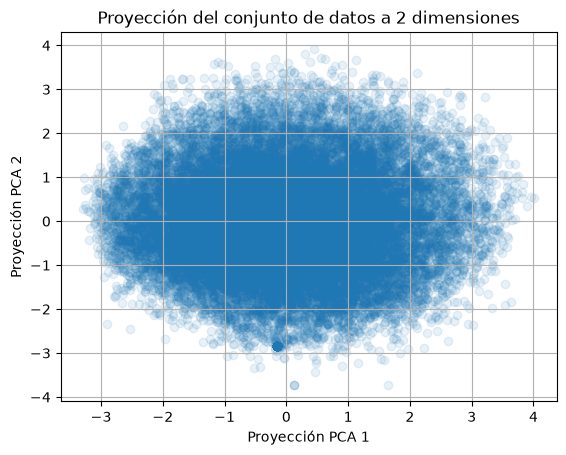

In [183]:

pca_transformado_3Variables = PCA(n_components=2)
# estandarizamos X
scaler = StandardScaler()
X_transformado_3Variables_scaled = scaler.fit_transform(df_sat_transformado_3Valores)
X_pca_transformado_3Variables = pca_transformado_3Variables.fit_transform(X_transformado_3Variables_scaled)

# graficamos los datos
plt.scatter(X_pca[:,0], X_pca[:,1], alpha=0.1)
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.show()

In [184]:
# Imprime la proporción de varianza de cada componente (en decimales)
print("Proporción de varianza explicada:", pca_transformado_3Variables.explained_variance_ratio_)

# Si lo quieres ver más lindo en formato porcentaje:
varianza_porcentual = pca_transformado_3Variables.explained_variance_ratio_ * 100
print(f"PC1 explica el: {varianza_porcentual[0]:.2f}%")
print(f"PC2 explica el: {varianza_porcentual[1]:.2f}%")
print(f"Varianza total explicada en 2D: {sum(varianza_porcentual):.2f}%")

Proporción de varianza explicada: [0.11402917 0.09029168]
PC1 explica el: 11.40%
PC2 explica el: 9.03%
Varianza total explicada en 2D: 20.43%


Vemos que no solo no aumentamos la cantidad de informacion recaudada por 2 variables, sino que se disminuyo:
Antes era:
[0.11917532 0.09330002]
Y ahora:
[0.11402917 0.09029168]

Graficamos el color de las respuestas en el scatter de PCA:

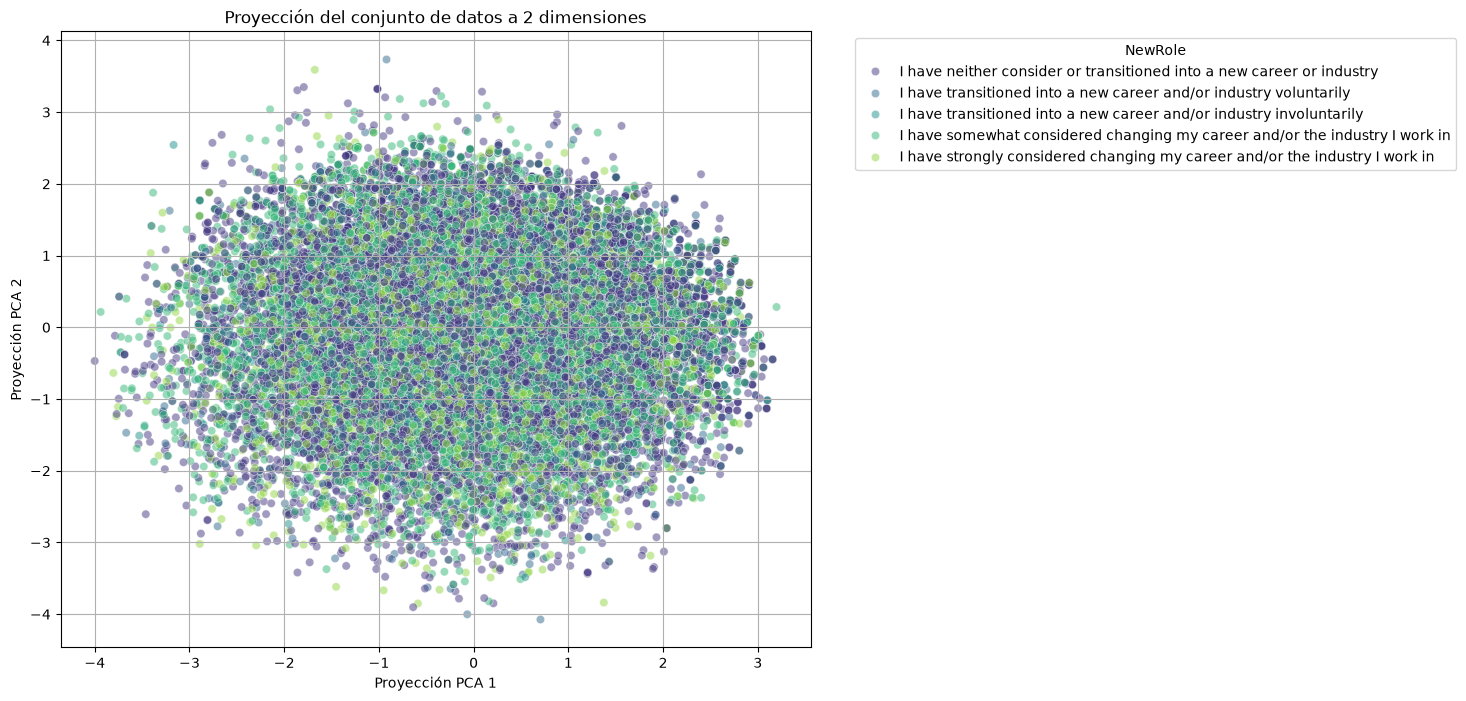

In [185]:
# 1. Hacemos la figura un poco más ancha de entrada (12 de ancho, 8 de alto)
# para que haya espacio natural para el gráfico + la leyenda
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_pca_transformado_3Variables[:,0], 
    y=X_pca_transformado_3Variables[:,1], 
    hue=df_limpio_c["NewRole"], 
    palette='viridis',
    alpha=0.5
)

plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')

# 2. Posicionamos la leyenda afuera como antes
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')

# 3. EL TRUCO PARA EVITAR EL ACHATAMIENTO:
# En lugar de usar plt.tight_layout(), forzamos a Matplotlib a dejar
# un margen específico a la derecha (en este caso, dejamos el gráfico
# ocupando solo hasta el 75% del ancho, dejando el 25% libre para la leyenda).
plt.subplots_adjust(right=0.75) 

plt.show()


Vemos relaciones no lineales con T-SNE:

Antes de t-SNE: (24729, 15)
Después de t-SNE: (24729, 2)


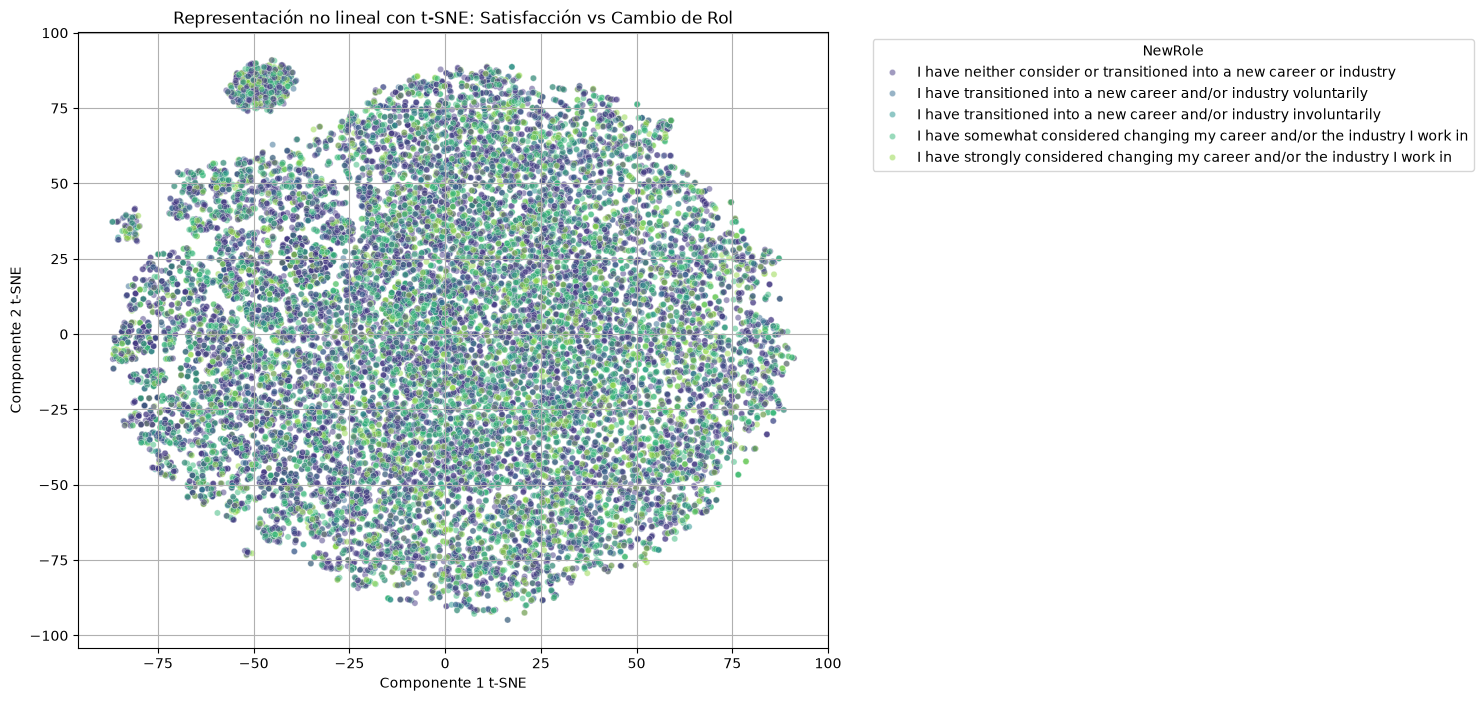

In [186]:
# 1. Aplicamos t-SNE sobre los datos ya estandarizados (X_scaled que usaste en PCA)
# Usamos random_state para que el resultado sea siempre el mismo si lo vuelves a correr
tsne = TSNE(n_components=2, random_state=42)
X_tsne_transformado = tsne.fit_transform(X_transformado_3Variables_scaled)

# Imprimimos los tamaños antes y después, como hace el profesor
print('Antes de t-SNE: {}'.format(X_transformado_3Variables_scaled.shape))
print('Después de t-SNE: {}'.format(X_tsne_transformado.shape))

# 2. Graficamos usando Seaborn para manejar correctamente las categorías de texto
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_tsne_transformado[:,0], 
    y=X_tsne_transformado[:,1], 
    hue=df_limpio_c["NewRole"], 
    palette='viridis',
    alpha=0.5,
    s=20 # Puntos pequeños para ver mejor las densidades
)

plt.grid(True)
plt.xlabel('Componente 1 t-SNE')
plt.ylabel('Componente 2 t-SNE')
plt.title('Representación no lineal con t-SNE: Satisfacción vs Cambio de Rol')

# Movemos la leyenda hacia afuera para evitar que tape el gráfico (igual que en PCA)
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

Vemos relaciones no lineales con UMAP:

/home/santirg/Escritorio/Tpe Fundamentos git lucas/TPE-Fundamentos-ciencia-datos/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Antes de UMAP: (24729, 15)
Después de UMAP: (24729, 2)


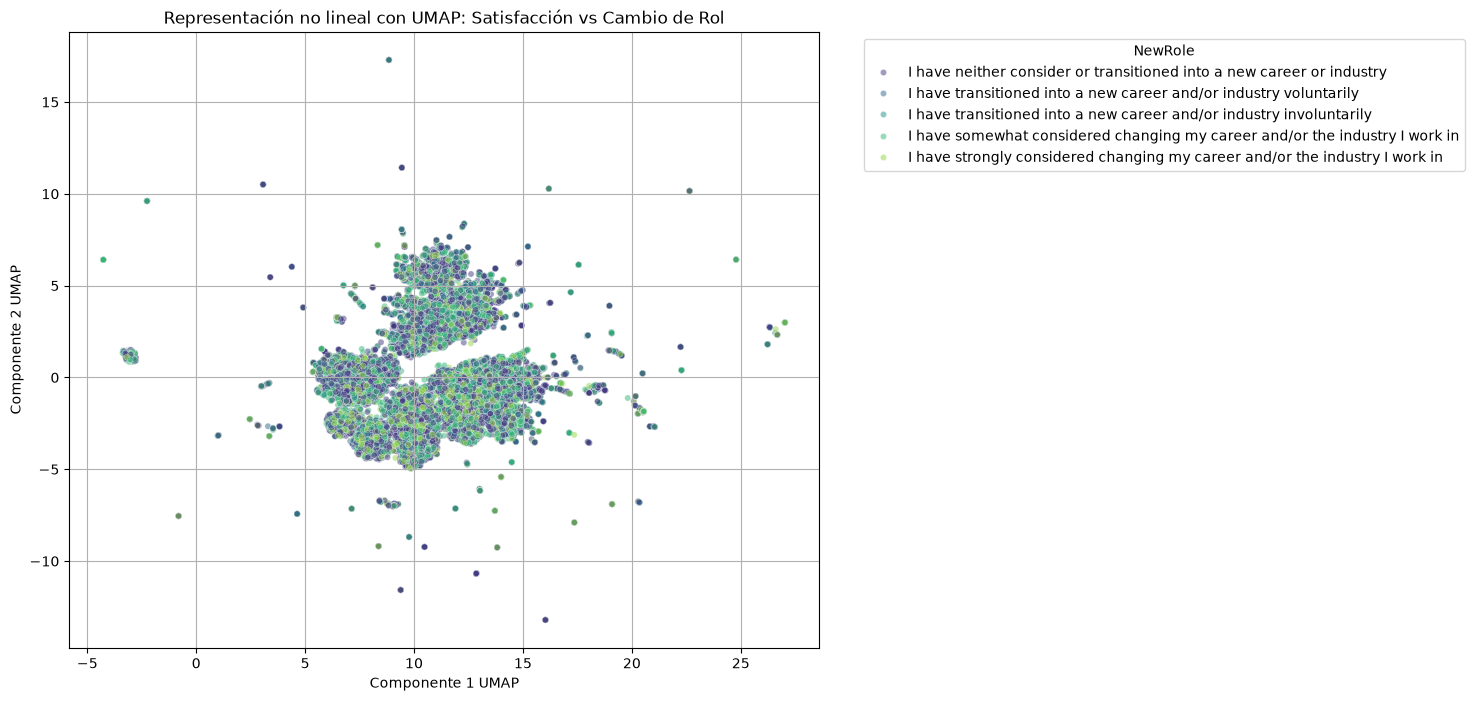

In [187]:
# importamos umap (Recuerda que si no lo tienes, debes ejecutar %pip install umap-learn)
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Creamos el objeto UMAP y lo aplicamos sobre nuestros datos ya estandarizados (X_scaled)
# Usar random_state te asegura que el gráfico salga exactamente igual cada vez que lo corras
reductor_umap = UMAP(n_components=2, random_state=42)
X_umap_transformado = reductor_umap.fit_transform(X_transformado_3Variables_scaled)

# Imprimimos los tamaños antes y después (para validar que la reducción se hizo bien)
print('Antes de UMAP: {}'.format(X_transformado_3Variables_scaled.shape))
print('Después de UMAP: {}'.format(X_umap_transformado.shape))

# 2. Configuramos el tamaño de la figura (más ancha para dar espacio a la leyenda)
plt.figure(figsize=(12, 8))

# 3. Graficamos usando Seaborn para manejar los textos de NewRole sin errores
sns.scatterplot(
    x=X_umap_transformado[:,0], 
    y=X_umap_transformado[:,1], 
    hue=df_limpio_c["NewRole"], 
    palette='viridis',
    alpha=0.5,
    s=20 # Achicamos el tamaño de los puntos para observar mejor la densidad
)

# 4. Estética del gráfico
plt.grid(True)
plt.xlabel('Componente 1 UMAP')
plt.ylabel('Componente 2 UMAP')
plt.title('Representación no lineal con UMAP: Satisfacción vs Cambio de Rol')

# 5. Movemos la leyenda fuera del gráfico y ajustamos el margen (para evitar que se achate)
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

Ya que la informacion recaudada con estas transformaciones sigue siendo muy baja, probemos con 5 posibles respuestas:
5- Muy importante
4- Importante
3- Neutral
2- No tan importante
1- No importante

In [188]:
# Creamos una copia para no alterar el original
df_sat_transformado_5Valores = X.copy()

# Definimos los límites (cortes de 3 en 3 para cubrir los 15 puestos)
bins = [0, 3, 6, 9, 12, 15] 

# Etiquetas numéricas ordenadas de mayor a menor importancia (5 es muy importante, 1 es no importante)
labels = [5, 4, 3, 2, 1]    

for col in cols_sat_float:
    # pd.cut agrupa los valores en los rangos definidos
    df_sat_transformado_5Valores [col] = pd.cut(df_sat_transformado_5Valores [col], bins=bins, labels=labels, right=True)
    # Convertimos a numérico por las dudas
    df_sat_transformado_5Valores [col] = pd.to_numeric(df_sat_transformado_5Valores [col])


In [189]:
df_sat_transformado_5Valores.head(3)

,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_15,JobSatPoints_16
0,5,5,4,3,4,2,2,2,5,4,3,1,1,1,3
1,2,3,5,3,2,5,4,5,2,4,3,1,1,1,4
2,3,4,3,2,3,2,5,4,5,4,5,1,1,1,2


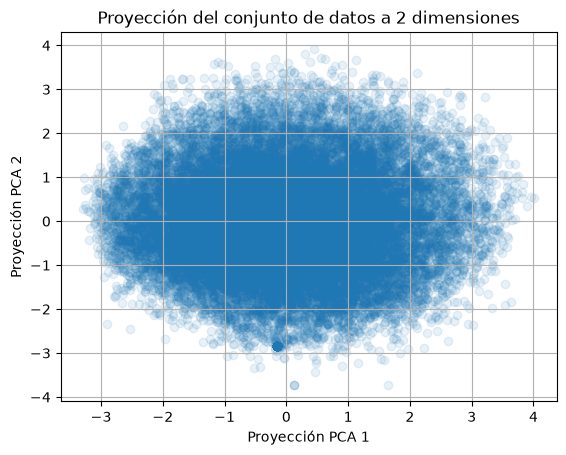

In [190]:
pca_transformado_5Variables = PCA(n_components=2)
# estandarizamos X
scaler = StandardScaler()
X_transformado_5Variables_scaled = scaler.fit_transform(df_sat_transformado_5Valores)
X_pca_transformado_5Variables = pca_transformado_5Variables.fit_transform(X_transformado_5Variables_scaled)

# graficamos los datos
plt.scatter(X_pca[:,0], X_pca[:,1], alpha=0.1)
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.show()

In [191]:
# Imprime la proporción de varianza de cada componente (en decimales)
print("Proporción de varianza explicada:", pca_transformado_5Variables.explained_variance_ratio_)

# Si lo quieres ver más lindo en formato porcentaje:
varianza_porcentual = pca_transformado_5Variables.explained_variance_ratio_ * 100
print(f"PC1 explica el: {varianza_porcentual[0]:.2f}%")
print(f"PC2 explica el: {varianza_porcentual[1]:.2f}%")
print(f"Varianza total explicada en 2D: {sum(varianza_porcentual):.2f}%")

Proporción de varianza explicada: [0.11704653 0.09237519]
PC1 explica el: 11.70%
PC2 explica el: 9.24%
Varianza total explicada en 2D: 20.94%


De esta forma se distribuyen las varianzas depende si hago transformaciones o no:
Sin transformacion (15 posibles valores) era:
[0.11917532 0.09330002] Aprox 21.25% con 2 variables

Con transformacion a 3 valores:
[0.11402917 0.09029168] Aprox 20.43%
Con transformacion a 5 valores:
[0.11704653 0.09237519] Aprox 20.94% 